In [1]:
import os
import json
from pathlib import Path
from collections import defaultdict

BASE_ROOT = Path("/kaggle/input/datasets")
SPLITS = ("train", "val", "test")

sample_records = defaultdict(list)
partition_audit = defaultdict(lambda: defaultdict(int))

user_dirs = [
    Path(e.path) for e in os.scandir(BASE_ROOT)
    if e.is_dir() and not e.name.startswith(".")
]

dataset_dirs = []
for u_dir in user_dirs:
    for e in os.scandir(u_dir):
        if e.is_dir() and not e.name.startswith("."):
            dataset_dirs.append(Path(e.path))

report_paths = []
for ds_root in dataset_dirs:
    candidates = [
        ds_root / "partition-report.json",
        ds_root / ds_root.name / "partition-report.json",
    ]
    for p in candidates:
        if p.is_file():
            report_paths.append(p)
            break

print(f"Directly located {len(report_paths)} report file(s).")
assert len(report_paths) == 6, f"Expected 6 partition reports, found {len(report_paths)}."

for report_path in report_paths:
    partition_root = report_path.parent
    report = json.loads(report_path.read_text())
    part_id = report.get("partition_id", partition_root.name)
    partition_key = f"partition-{part_id:02d}" if isinstance(part_id, int) else str(part_id)

    for shard in report.get("shards", []):
        split = shard["split"]
        shard_tar_name = Path(shard["path"]).name
        shard_folder = shard_tar_name.replace(".tar", "")

        target_dir = partition_root / split / shard_folder
        if not target_dir.is_dir():
            target_dir = partition_root / split

        if not target_dir.is_dir():
            continue

        with os.scandir(target_dir) as entries:
            for entry in entries:
                if entry.name.endswith(".rgb.png") and not entry.name.startswith("."):
                    base_prefix = str(target_dir / entry.name[:-8])
                    sample_records[split].append(base_prefix)
                    partition_audit[partition_key][split] += 1

print("\n--- Dataset Indexing Summary ---")
for split in SPLITS:
    print(f"Total {split.upper()} samples indexed: {len(sample_records[split])}")

Directly located 6 report file(s).

--- Dataset Indexing Summary ---
Total TRAIN samples indexed: 20016
Total VAL samples indexed: 3436
Total TEST samples indexed: 11444


In [2]:
import os
import json
import numpy as np
import torch
from pathlib import Path
from collections import defaultdict
from torch.utils.data import Dataset, DataLoader
from PIL import Image

class GamusDiskDataset(Dataset):
    def __init__(self, sample_prefixes):
        self.sample_prefixes = sample_prefixes

    def __len__(self):
        return len(self.sample_prefixes)

    def __getitem__(self, idx):
        prefix = self.sample_prefixes[idx]
        
        rgb = np.array(Image.open(f"{prefix}.rgb.png").convert("RGB"))
        rgb_tensor = torch.from_numpy(rgb).permute(2, 0, 1).float() / 255.0
        
        height = np.load(f"{prefix}.height.npy").astype(np.float32)
        height_tensor = torch.from_numpy(height).unsqueeze(0)
        
        valid_path = f"{prefix}.valid.png"
        if os.path.exists(valid_path):
            valid_mask = np.array(Image.open(valid_path).convert("L"))
            valid_tensor = torch.from_numpy(valid_mask).unsqueeze(0) > 127
        else:
            valid_tensor = torch.ones_like(height_tensor, dtype=torch.bool)

        # CONTRACT: finite and not exact -5.0. Preserve negative labels, do not clamp.
        valid_tensor = valid_tensor & torch.isfinite(height_tensor) & (height_tensor != -5.0)
        height_tensor[~valid_tensor] = 0.0 

        return {"rgb": rgb_tensor, "height": height_tensor, "valid_mask": valid_tensor}

# --- STRICT GEOGRAPHIC HOLDOUT SPLIT FOR TRAINING ---
# Group by source tile to prevent data leakage (keeps all 4 crops together)
tile_groups = defaultdict(list)
for p in sample_records['train']:
    base_name = Path(p).name  # e.g., "train-DC_29_13--se"
    tile_id = base_name.split('--')[1]  # e.g., "DC_29_13"
    tile_groups[tile_id].append(p)

sorted_tiles = sorted(list(tile_groups.keys()))
train_tiles = sorted_tiles[::2]

# Training uses 50% of the source tiles (but ALL 4 crops for each selected tile)
train_prefixes = [p for t in train_tiles for p in tile_groups[t]]

# --- FIX: Explicitly include 50% of the VALIDATION split for evaluation ---
val_prefixes = sample_records["val"][::2]

train_dataset = GamusDiskDataset(train_prefixes)
val_dataset = GamusDiskDataset(val_prefixes)

train_loader = DataLoader(
    train_dataset, 
    batch_size=4, 
    shuffle=True, 
    num_workers=2, 
    pin_memory=True, 
    drop_last=True
)
val_loader = DataLoader(
    val_dataset, 
    batch_size=1, 
    shuffle=False, 
    num_workers=2, 
    pin_memory=True
)

print(f"DataLoaders built successfully:")
print(f" - Train Tiles (Geographic 50%): {len(train_tiles)} | Total Train Crops: {len(train_prefixes)}")
print(f" - Val Crops (Explicit 50% Subsample): {len(val_prefixes)}")
print(f" - Train steps per epoch: {len(train_loader)}")
print(f" - Val steps per epoch: {len(val_loader)}")

DataLoaders built successfully:
 - Train Tiles (Geographic 50%): 2502 | Total Train Crops: 10008
 - Val Crops (Explicit 50% Subsample): 1718
 - Train steps per epoch: 2502
 - Val steps per epoch: 1718


In [3]:
# from torch.utils.data import DataLoader
# from collections import defaultdict

# # --- CONTRACT UPDATE: Geographic Holdout Split ---
# # Group samples by source tile ID to ensure all 4 crops stay together
# tile_groups = defaultdict(list)
# for prefix in sample_records["train"]:
#     # Assuming prefix format is "tileID_cropType" (e.g., "nyc_001_nw")
#     # Adjust the split logic if your naming convention differs
#     tile_id = "_".join(prefix.split("_")[:-1]) 
#     tile_groups[tile_id].append(prefix)

# # Deterministic 50% source-level selection for training, rest for geo-holdout validation
# sorted_tiles = sorted(list(tile_groups.keys()))
# train_tiles = sorted_tiles[::2]
# geo_holdout_tiles = sorted_tiles[1::2]

# train_subset_prefixes = []
# for tile in train_tiles:
#     train_subset_prefixes.extend(tile_groups[tile])

# # For Phase B validation, we use the geographic holdout to test generalization
# val_subset_prefixes = []
# for tile in geo_holdout_tiles:
#     val_subset_prefixes.extend(tile_groups[tile])

# train_dataset = GamusDiskDataset(train_subset_prefixes)
# val_dataset = GamusDiskDataset(val_subset_prefixes)

# train_loader = DataLoader(
#     train_dataset,
#     batch_size=2,
#     shuffle=True,
#     num_workers=4,
#     pin_memory=True,
#     drop_last=True
# )

# val_loader = DataLoader(
#     val_dataset,
#     batch_size=1,
#     shuffle=False,
#     num_workers=2,
#     pin_memory=True,
# )

# print(f"DataLoaders successfully built with Geographic Holdout:")
# print(f" - Train steps per epoch: {len(train_loader)}")
# print(f" - Geo-Holdout Val steps per epoch: {len(val_loader)}")

In [4]:
import sys
import torch
import torch.nn as nn
import torch.nn.functional as F
from pathlib import Path

# Locate DA-V2 repo
NBDIR = Path("/kaggle/input/notebooks/boxedinthecube/dav2-traina-cls-1")
dpt_candidates = list(NBDIR.rglob("dpt.py"))
repo_parent = str(next(p for p in dpt_candidates if p.parent.name == "depth_anything_v2").parent.parent)
assert repo_parent is not None, "Could not find 'depth_anything_v2/dpt.py' in /kaggle/input."
if repo_parent not in sys.path: sys.path.insert(0, repo_parent)
from depth_anything_v2.dpt import DepthAnythingV2

# 2. Matching Architecture
class ResidualScaleAdapter(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.adapter = nn.Sequential(
            nn.LayerNorm(dim),
            nn.Linear(dim, dim // 4),
            nn.GELU(),
            nn.Linear(dim // 4, dim),
        )
        nn.init.zeros_(self.adapter[-1].weight)
        nn.init.zeros_(self.adapter[-1].bias)

    def forward(self, x):
        if isinstance(x, tuple):
            tokens, cls_token = x
            return (tokens + self.adapter(tokens), cls_token)
        return x + self.adapter(x)

class MultiScaleHeightHead(nn.Module):
    def __init__(
        self, in_channels=1, hidden_dim=32):
        super().__init__()
        self.affine_conv = nn.Conv2d(in_channels, 1, kernel_size=1)
        nn.init.constant_(self.affine_conv.weight, 15.0)
        nn.init.constant_(self.affine_conv.bias, 2.0)

        self.refiner = nn.Sequential(
            nn.Conv2d(in_channels, hidden_dim, kernel_size=3, padding=1),
            nn.GroupNorm(4, hidden_dim),
            nn.GELU(),
            nn.Conv2d(hidden_dim, 1, kernel_size=1)
        )
        
        self.uncertainty_head = nn.Sequential(
            nn.Conv2d(in_channels, hidden_dim // 2, kernel_size=3, padding=1),
            nn.GroupNorm(4, hidden_dim // 2),
            nn.GELU(),
            nn.Conv2d(hidden_dim // 2, 1, kernel_size=1)
        )

    def forward(self, raw_depth, target_size=(518, 518)):
        if raw_depth.ndim == 3:
            raw_depth = raw_depth.unsqueeze(1)

        base_metric = self.affine_conv(raw_depth)
        residual = self.refiner(raw_depth)
        
        # --- CONTRACT UPDATE: Unbounded linear output (no ReLU clamping) ---
        h = base_metric + residual 
        
        h = F.interpolate(h, size=target_size, mode="bilinear", align_corners=False)
        log_var = F.interpolate(self.uncertainty_head(raw_depth), size=target_size, mode="bilinear", align_corners=False)
        return h, log_var

class DepthAnythingV2GAMUS(nn.Module):
    def __init__(self, base_model):
        super().__init__()
        self.pretrained = base_model
        embed_dim = 768
        self.adapters = nn.ModuleList([ResidualScaleAdapter(embed_dim) for _ in range(4)])
        self.head = MultiScaleHeightHead(in_channels=1, hidden_dim=32)

    def forward(self, x):
        patch_h, patch_w = x.shape[-2] // 14, x.shape[-1] // 14
        intermediate_features = self.pretrained.pretrained.get_intermediate_layers(
            x, 4, return_class_token=True
        )

        adapted_features = []
        for i, feat in enumerate(intermediate_features):
            # Let the adapter handle the structure safely without unpacking the batch dim
            adapted_feat = self.adapters[i](feat) 
            adapted_features.append(adapted_feat)

        raw_depth = self.pretrained.depth_head(adapted_features, patch_h, patch_w)
        if raw_depth.ndim == 3: raw_depth = raw_depth.unsqueeze(1)
        if raw_depth.shape[-2:] != x.shape[-2:]:
            raw_depth = F.interpolate(raw_depth, size=x.shape[-2:], mode="bilinear", align_corners=False)

        pred_height_m, log_var = self.head(raw_depth.float(), target_size=x.shape[-2:])
        
        # CONTRACT: Lock primary output key
        return {"metric_nDSM": pred_height_m, "uncertainty_log_var": log_var, "decoder_features": raw_depth}

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_configs = {'vitb': {'encoder': 'vitb', 'features': 128, 'out_channels': [96, 192, 384, 768]}}
raw_da_v2 = DepthAnythingV2(**model_configs['vitb'])
model = DepthAnythingV2GAMUS(raw_da_v2).to(device)

# Load Phase A Checkpoint
ckpt_path = Path("/kaggle/input/notebooks/boxedinthecube/dav2-traina-cls-1/checkpoints_phase_a/last_checkpoint.pt")
checkpoint = torch.load(ckpt_path, map_location=device)
state_dict = {k.replace("module.", ""): v for k, v in checkpoint["model_state_dict"].items()}
model.load_state_dict(state_dict)
print("Successfully loaded Phase A weights.")

# Phase B Freezing Strategy: Unfreeze ONLY the last 4 ViT blocks
raw_m = model.module if isinstance(model, nn.DataParallel) else model
for param in raw_m.pretrained.parameters():
    param.requires_grad = False # Freeze all first

for block in raw_m.pretrained.pretrained.blocks[-4:]: # Unfreeze last 4 blocks
    for param in block.parameters():
        param.requires_grad = True

# Ensure heads and adapters remain trainable
for param in raw_m.adapters.parameters(): param.requires_grad = True
for param in raw_m.head.parameters(): param.requires_grad = True

if torch.cuda.device_count() > 1:
    model = nn.DataParallel(model)

trainable_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Phase B Model Ready. Trainable Params: {trainable_count:,}")

xFormers not available
xFormers not available


Successfully loaded Phase A weights.
Phase B Model Ready. Trainable Params: 29,547,892


In [5]:
# 0. Unwrap DataParallel to access the actual model architecture
raw_model = model.module if isinstance(model, nn.DataParallel) else model

# 1. Reset all backbone parameters to frozen
for param in raw_model.pretrained.parameters():
    param.requires_grad = False

# 2. Keep head, adapters, and DPT decoder active
for param in raw_model.head.parameters():
    param.requires_grad = True
for param in raw_model.adapters.parameters():
    param.requires_grad = True
for param in raw_model.pretrained.depth_head.parameters():
    param.requires_grad = True

# 3. Selective Unfreezing: Last 4 ViT blocks (blocks 8, 9, 10, 11)
vit_blocks = raw_model.pretrained.pretrained.blocks
UNFREEZE_LAST_N_BLOCKS = 4

for block in vit_blocks[-UNFREEZE_LAST_N_BLOCKS:]:
    for param in block.parameters():
        param.requires_grad = True

# 4. Re-wrap in DataParallel if it was originally wrapped
if torch.cuda.device_count() > 1 and not isinstance(model, nn.DataParallel):
    print(f"Enabling DataParallel across {torch.cuda.device_count()} GPUs.")
    model = nn.DataParallel(raw_model)

trainable_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
frozen_count = sum(p.numel() for p in model.parameters() if not p.requires_grad)
print(f"Phase B Model Parameters: {trainable_count:,} Trainable | {frozen_count:,} Frozen")

Phase B Model Parameters: 40,438,197 Trainable | 58,222,848 Frozen


In [6]:
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR

# 1. Compound Loss (Includes Uncertainty NLL from Phase A)
class CompoundGAMUSLoss(nn.Module):
    def __init__(self, w_metric=1.0, w_si=1.0, w_grad=0.05, w_uncert=0.1):
        super().__init__()
        self.w_metric, self.w_si, self.w_grad, self.w_uncert = w_metric, w_si, w_grad, w_uncert
        self.huber = nn.HuberLoss(delta=1.0, reduction="none")

    def gradient_loss(self, pred, target, mask):
        diff_y_pred = torch.abs(pred[:, :, 1:, :] - pred[:, :, :-1, :])
        diff_x_pred = torch.abs(pred[:, :, :, 1:] - pred[:, :, :, :-1])
        diff_y_targ = torch.abs(target[:, :, 1:, :] - target[:, :, :-1, :])
        diff_x_targ = torch.abs(target[:, :, :, 1:] - target[:, :, :, :-1])
        mask_y = mask[:, :, 1:, :] & mask[:, :, :-1, :]
        mask_x = mask[:, :, :, 1:] & mask[:, :, :, :-1]
        loss_y = torch.abs(diff_y_pred - diff_y_targ)[mask_y].mean() if mask_y.any() else torch.tensor(0.0, device=pred.device)
        loss_x = torch.abs(diff_x_pred - diff_x_targ)[mask_x].mean() if mask_x.any() else torch.tensor(0.0, device=pred.device)
        return loss_y + loss_x

    def forward(self, outputs, targets, valid_masks):
        preds = outputs["metric_nDSM"]
        log_vars = outputs["uncertainty_log_var"]
        mask = (valid_masks > 0.5) & torch.isfinite(targets) & (targets != -5.0)
        
        if not mask.any():
            zero = preds.sum() * 0.0
            return {"total_loss": zero, "metric_loss": zero, "si_loss": zero, "grad_loss": zero, "uncertainty_loss": zero}

        p_valid, t_valid, log_var_valid = preds[mask], targets[mask], log_vars[mask]
        metric_loss = self.huber(p_valid, t_valid).mean()
        
        p_log = torch.log(torch.clamp(p_valid, min=1e-7, max=250.0))
        t_log = torch.log(torch.clamp(t_valid, min=1e-7, max=250.0))
        d = p_log - t_log
        n = torch.clamp(mask.sum(), min=1.0)
        si_loss = (d ** 2).sum() / n - 0.15 * ((d.sum() / n) ** 2)
        
        grad_loss = self.gradient_loss(preds, targets, mask)
        
        log_var_clamped = torch.clamp(log_var_valid, min=-10.0, max=10.0)
        uncertainty_loss = 0.5 * ((p_valid - t_valid)**2 / torch.exp(log_var_clamped) + log_var_clamped).mean()

        total_loss = self.w_metric * metric_loss + self.w_si * si_loss + self.w_grad * grad_loss + self.w_uncert * uncertainty_loss
        return {"total_loss": total_loss, "metric_loss": metric_loss, "si_loss": si_loss, "grad_loss": grad_loss, "uncertainty_loss": uncertainty_loss}

criterion = CompoundGAMUSLoss(w_metric=1.0, w_si=1.0, w_grad=0.05, w_uncert=0.1).to(device)

# 2. Optimizer with Discriminative Learning Rates
raw_m = model.module if isinstance(model, nn.DataParallel) else model
unfrozen_vit_params = [p for block in raw_m.pretrained.pretrained.blocks[-4:] for p in block.parameters() if p.requires_grad]
decoder_params = [p for n, p in raw_m.pretrained.named_parameters() if p.requires_grad and "depth_head" in n]
refiner_and_uncert_params = list(raw_m.head.refiner.parameters()) + list(raw_m.head.uncertainty_head.parameters())
adapter_params = list(raw_m.adapters.parameters())
affine_params = list(raw_m.head.affine_conv.parameters())

optimizer = AdamW([
    {"params": unfrozen_vit_params, "lr": 5e-6, "weight_decay": 1e-2},
    {"params": decoder_params, "lr": 2e-5, "weight_decay": 1e-2},
    {"params": refiner_and_uncert_params, "lr": 1e-4, "weight_decay": 1e-4},
    {"params": adapter_params, "lr": 1e-4, "weight_decay": 1e-2},
    {"params": affine_params, "lr": 2e-4, "weight_decay": 0.0}
])

NUM_EPOCHS_B = 3
TOTAL_STEPS_B = (len(train_loader) // 8) * NUM_EPOCHS_B
scheduler = CosineAnnealingLR(optimizer, T_max=TOTAL_STEPS_B, eta_min=1e-6)
scaler = torch.amp.GradScaler("cuda")
print(f"Phase B Optimizer Ready. Total Steps: {TOTAL_STEPS_B}")

Phase B Optimizer Ready. Total Steps: 936


In [7]:
# 1. Fetch a single batch
batch = next(iter(train_loader))
images = batch["rgb"]

print("--- DataLoader Output Inspection ---")
print(f"1. Type of 'images': {type(images)}")
print(f"2. Shape of 'images': {images.shape if hasattr(images, 'shape') else 'NO SHAPE (might be a list)'}")
print(f"3. Dtype of 'images': {images.dtype}")

# 2. Apply the bulletproof fix
if isinstance(images, list):
    print("WARNING: 'images' is a list! Stacking it...")
    images = torch.stack(images)
    
while images.ndim < 4:
    images = images.unsqueeze(0)

images = images.to(device)
print(f"4. Shape AFTER fix and .to(device): {images.shape}")
print("------------------------------------")

# 3. Test a single forward pass
raw_model = model.module if isinstance(model, nn.DataParallel) else model
try:
    with torch.no_grad():
        # We only pass it through the ViT backbone to isolate the error
        _ = raw_model.pretrained.pretrained(images)
    print("✅ SUCCESS: ViT backbone forward pass completed without errors.")
except RuntimeError as e:
    print(f"❌ FAILED: ViT backbone crashed with: {e}")

--- DataLoader Output Inspection ---
1. Type of 'images': <class 'torch.Tensor'>
2. Shape of 'images': torch.Size([4, 3, 518, 518])
3. Dtype of 'images': torch.float32
4. Shape AFTER fix and .to(device): torch.Size([4, 3, 518, 518])
------------------------------------
✅ SUCCESS: ViT backbone forward pass completed without errors.


In [8]:
import torch.nn as nn

raw_model = model.module if isinstance(model, nn.DataParallel) else model
vit_backbone = raw_model.pretrained.pretrained

# 1. Define a hook function that prints input shapes
def debug_hook(module, input, output):
    # We only care about the first input tensor
    in_tensor = input[0]
    if hasattr(in_tensor, 'shape'):
        print(f"Layer: {module.__class__.__name__:<20} | Input Shape: {tuple(in_tensor.shape)}")
    else:
        print(f"Layer: {module.__class__.__name__:<20} | Input Type: {type(in_tensor)}")

# 2. Register hooks on the Patch Embedder and the first few ViT blocks
hooks = []
hooks.append(vit_backbone.patch_embed.register_forward_hook(debug_hook))
for i, block in enumerate(vit_backbone.blocks[:4]): # Check first 4 blocks
    hooks.append(block.register_forward_hook(debug_hook))

# 3. Run the forward pass
print("--- Layer-by-Layer Execution Trace ---")
try:
    with torch.no_grad():
        _ = raw_model.pretrained.pretrained(images)
    print("✅ SUCCESS: Forward pass completed.")
except RuntimeError as e:
    print(f"\n❌ CRASHED HERE! Error: {e}")
finally:
    # 4. Clean up hooks
    for h in hooks:
        h.remove()

--- Layer-by-Layer Execution Trace ---
Layer: PatchEmbed           | Input Shape: (4, 3, 518, 518)
Layer: NestedTensorBlock    | Input Shape: (4, 1370, 768)
Layer: NestedTensorBlock    | Input Shape: (4, 1370, 768)
Layer: NestedTensorBlock    | Input Shape: (4, 1370, 768)
Layer: NestedTensorBlock    | Input Shape: (4, 1370, 768)
✅ SUCCESS: Forward pass completed.


In [9]:
import traceback

batch = next(iter(train_loader))
images = batch["rgb"].to(device, non_blocking=True)
targets = batch["height"].to(device, non_blocking=True)
valid_masks = batch["valid_mask"].to(device, non_blocking=True)

# Force 4D
while images.ndim < 4: images = images.unsqueeze(0)
while targets.ndim < 4: targets = targets.unsqueeze(0)
while valid_masks.ndim < 4: valid_masks = valid_masks.unsqueeze(0)

print(f"Input shape: {images.shape}")
print(f"Is DataParallel: {isinstance(model, nn.DataParallel)}")

# Test with Autocast and Full Traceback
try:
    with torch.autocast(device_type="cuda", dtype=torch.float16):
        outputs = model(images)
    print("✅ SUCCESS: Forward pass with autocast worked.")
except Exception as e:
    print(f"❌ FAILED with autocast: {e}")
    print("\n--- FULL INTERNAL TRACEBACK ---")
    traceback.print_exc()

Input shape: torch.Size([4, 3, 518, 518])
Is DataParallel: True
✅ SUCCESS: Forward pass with autocast worked.


In [10]:
import time
from pathlib import Path

CHECKPOINT_DIR = Path("/kaggle/working/checkpoints_phase_b")
CHECKPOINT_DIR.mkdir(exist_ok=True, parents=True)

model.train()
optimizer.zero_grad(set_to_none=True)
step_counter, running_loss, running_m, running_si, running_g, running_u = 0, 0.0, 0.0, 0.0, 0.0, 0.0
start_time = time.perf_counter()
GRADIENT_ACCUMULATION_STEPS = 8

history_b = {"step": [], "total_loss": [], "metric_loss": [], "si_loss": [], "grad_loss": [], "uncertainty_loss": []}

print(f"Beginning Phase B Fine-Tuning ({NUM_EPOCHS_B} epochs, ~{TOTAL_STEPS_B} steps)...")

for epoch in range(1, NUM_EPOCHS_B + 1):
    for batch_idx, batch in enumerate(train_loader, start=1):
        images = batch["rgb"].to(device, non_blocking=True)
        targets = batch["height"].to(device, non_blocking=True)
        valid_masks = batch["valid_mask"].to(device, non_blocking=True)
        
        # --- BULLETPROOF FIX: Force 4D tensors [B, C, H, W] ---
        while images.ndim < 4:
            images = images.unsqueeze(0)
        while targets.ndim < 4:
            targets = targets.unsqueeze(0)
        while valid_masks.ndim < 4:
            valid_masks = valid_masks.unsqueeze(0)
        
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            outputs = model(images)
            loss_dict = criterion(outputs, targets, valid_masks)
            loss = loss_dict["total_loss"] / GRADIENT_ACCUMULATION_STEPS
            
        scaler.scale(loss).backward()
        
        running_loss += loss.item() * GRADIENT_ACCUMULATION_STEPS
        running_m += loss_dict["metric_loss"].item()
        running_si += loss_dict["si_loss"].item()
        running_g += loss_dict["grad_loss"].item()
        running_u += loss_dict["uncertainty_loss"].item()

        if batch_idx % GRADIENT_ACCUMULATION_STEPS == 0:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            
            # --- FIX: Correct scheduler step order ---
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            optimizer.zero_grad(set_to_none=True)
            step_counter += 1

            if step_counter % 25 == 0:
                num_micro = 25.0 * GRADIENT_ACCUMULATION_STEPS
                avg_l = running_loss / 25.0
                avg_m, avg_s, avg_g, avg_u = running_m/num_micro, running_si/num_micro, running_g/num_micro, running_u/num_micro
                
                history_b["step"].append(step_counter)
                history_b["total_loss"].append(avg_l)
                history_b["metric_loss"].append(avg_m)
                history_b["si_loss"].append(avg_s)
                history_b["grad_loss"].append(avg_g)
                history_b["uncertainty_loss"].append(avg_u)

                print(f"Epoch [{epoch}/{NUM_EPOCHS_B}]| Step {step_counter}/{TOTAL_STEPS_B}| Loss: {avg_l:.4f} (M:{avg_m:.3f}, SI:{avg_s:.3f}, G:{avg_g:.3f}, U:{avg_u:.3f})| LR: {scheduler.get_last_lr()[0]:.7f}")
                running_loss, running_m, running_si, running_g, running_u = 0.0, 0.0, 0.0, 0.0, 0.0

            if step_counter % 100 == 0:
                torch.save({"epoch": epoch, "global_step": step_counter, "model_state_dict": raw_m.state_dict(), "optimizer_state_dict": optimizer.state_dict()}, CHECKPOINT_DIR / "last_checkpoint.pt")

    # End of epoch checkpoint
    torch.save({"epoch": epoch, "global_step": step_counter, "model_state_dict": raw_m.state_dict()}, CHECKPOINT_DIR / f"phase_b_epoch_{epoch}.pt")
    print(f"--> Saved Epoch {epoch} Checkpoint")

print("\nPhase B Fine-Tuning Complete!")

Beginning Phase B Fine-Tuning (3 epochs, ~936 steps)...


/tmp/ipykernel_23/250345466.py:51: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


Epoch [1/3]| Step 25/936| Loss: 279.4586 (M:2.385, SI:32.239, G:1.146, U:2.509)| LR: 0.0000050
Epoch [1/3]| Step 50/936| Loss: 311.6302 (M:2.457, SI:36.182, G:1.031, U:2.630)| LR: 0.0000050
Epoch [1/3]| Step 75/936| Loss: 384.1756 (M:2.432, SI:45.274, G:1.060, U:2.635)| LR: 0.0000049
Epoch [1/3]| Step 100/936| Loss: 370.2298 (M:2.491, SI:43.462, G:1.119, U:2.693)| LR: 0.0000049
Epoch [1/3]| Step 125/936| Loss: 363.2906 (M:2.492, SI:42.595, G:1.018, U:2.732)| LR: 0.0000048
Epoch [1/3]| Step 150/936| Loss: 335.1770 (M:2.504, SI:39.074, G:1.051, U:2.660)| LR: 0.0000048
Epoch [1/3]| Step 175/936| Loss: 361.5366 (M:2.542, SI:42.333, G:1.093, U:2.620)| LR: 0.0000047
Epoch [1/3]| Step 200/936| Loss: 401.9245 (M:2.439, SI:47.508, G:0.987, U:2.447)| LR: 0.0000046
Epoch [1/3]| Step 225/936| Loss: 311.8839 (M:2.394, SI:36.287, G:1.156, U:2.470)| LR: 0.0000045
Epoch [1/3]| Step 250/936| Loss: 317.3986 (M:2.425, SI:36.952, G:1.170, U:2.390)| LR: 0.0000043
Epoch [1/3]| Step 275/936| Loss: 346.4288 (

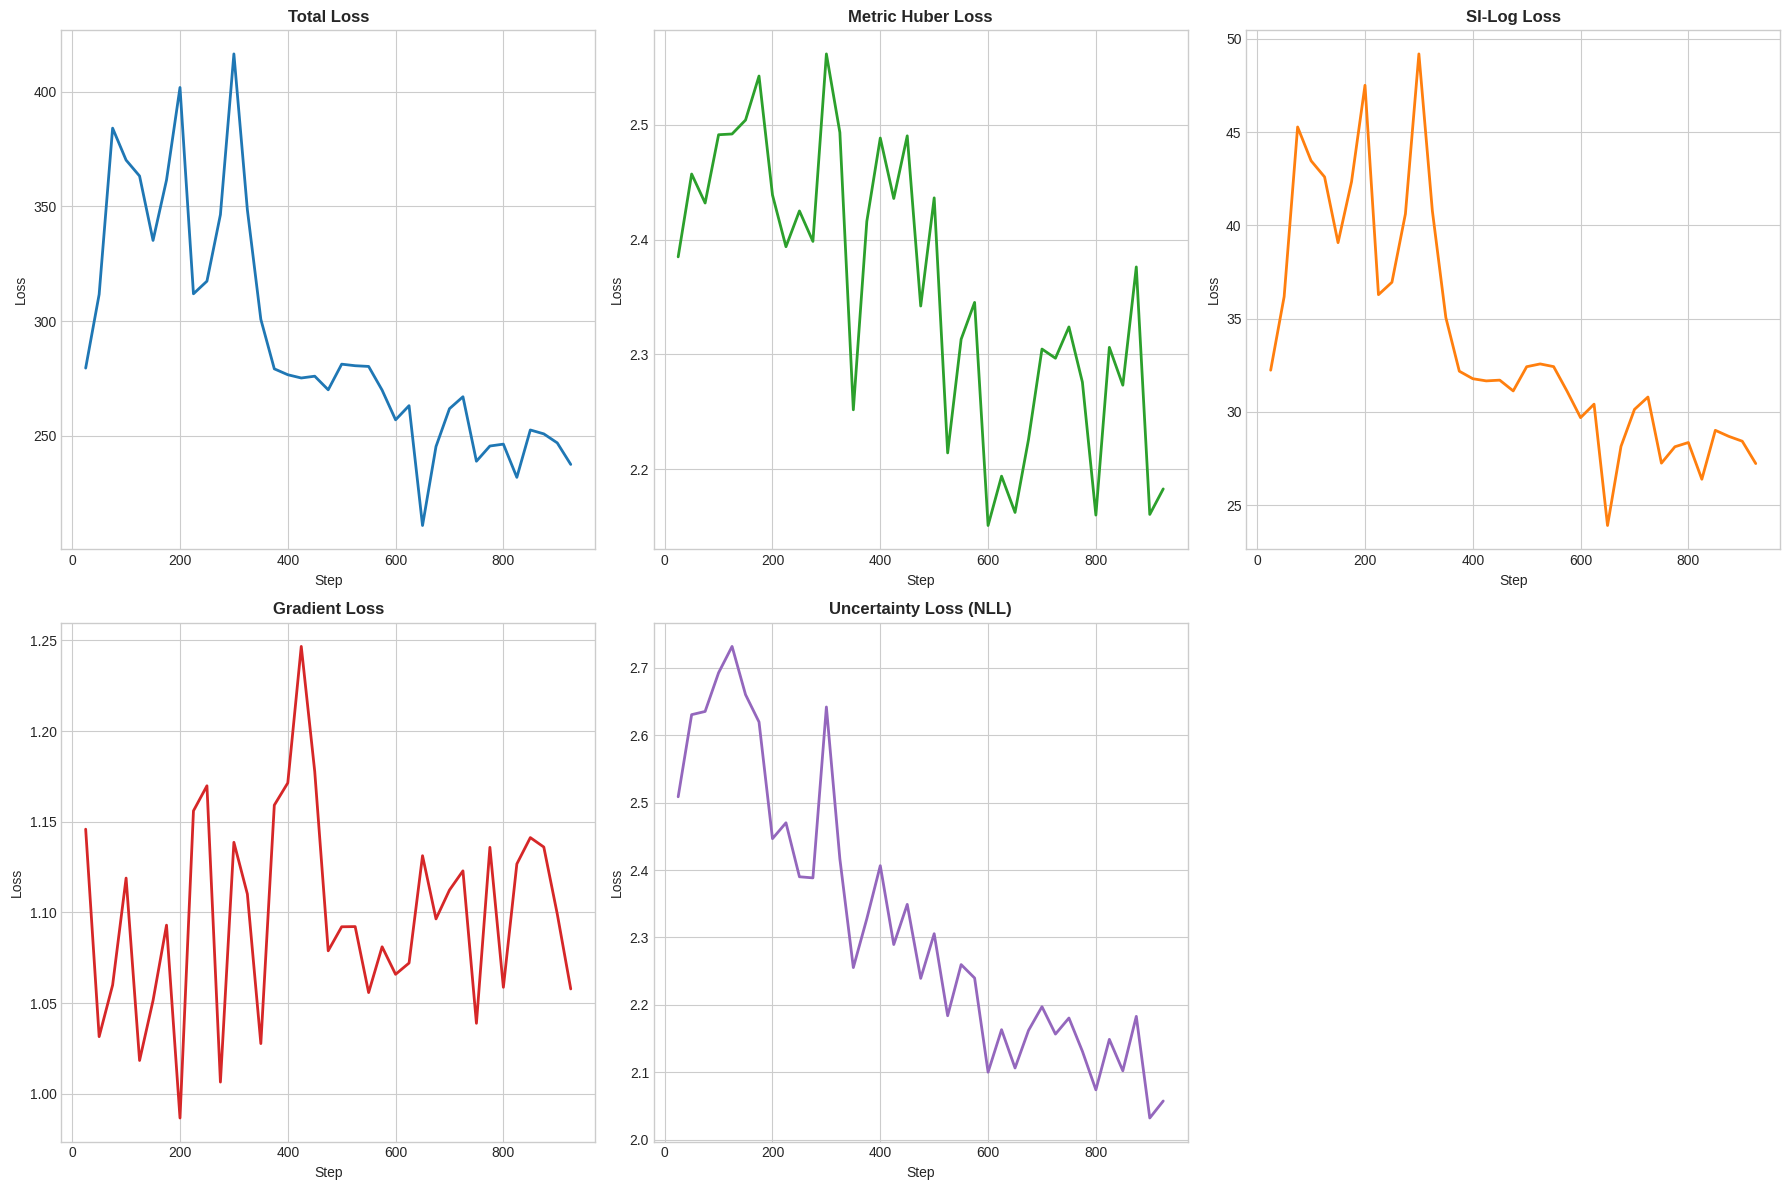

Saved phase_b_training_losses.png


In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(18, 12))
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")

plt.subplot(2, 3, 1)
plt.plot(history_b["step"], history_b["total_loss"], color="#1f77b4", linewidth=2)
plt.title("Total Loss", fontweight="bold"); plt.xlabel("Step"); plt.ylabel("Loss")

plt.subplot(2, 3, 2)
plt.plot(history_b["step"], history_b["metric_loss"], color="#2ca02c", linewidth=2)
plt.title("Metric Huber Loss", fontweight="bold"); plt.xlabel("Step"); plt.ylabel("Loss")

plt.subplot(2, 3, 3)
plt.plot(history_b["step"], history_b["si_loss"], color="#ff7f0e", linewidth=2)
plt.title("SI-Log Loss", fontweight="bold"); plt.xlabel("Step"); plt.ylabel("Loss")

plt.subplot(2, 3, 4)
plt.plot(history_b["step"], history_b["grad_loss"], color="#d62728", linewidth=2)
plt.title("Gradient Loss", fontweight="bold"); plt.xlabel("Step"); plt.ylabel("Loss")

plt.subplot(2, 3, 5)
plt.plot(history_b["step"], history_b["uncertainty_loss"], color="#9467bd", linewidth=2)
plt.title("Uncertainty Loss (NLL)", fontweight="bold"); plt.xlabel("Step"); plt.ylabel("Loss")

plt.tight_layout()
plt.savefig("/kaggle/working/phase_b_training_losses.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved phase_b_training_losses.png")

In [12]:
import numpy as np

model.eval()
val_mae_list, val_rmse_list = [], []
MAX_VAL_SAMPLES = 200

print(f"Beginning Phase B Validation on Geographic Holdout (up to {MAX_VAL_SAMPLES} crops)...")

with torch.no_grad():
    for idx, batch in enumerate(val_loader, start=1):
        if MAX_VAL_SAMPLES is not None and idx > MAX_VAL_SAMPLES: break

        images = batch["rgb"].to(device, non_blocking=True)
        targets = batch["height"].to(device, non_blocking=True)
        valid_masks = batch["valid_mask"].to(device, non_blocking=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            outputs = model(images)
            preds = outputs["metric_nDSM"]

        mask = (valid_masks > 0.5) & torch.isfinite(targets) & (targets != -5.0)
        if not mask.any(): continue

        p_valid, t_valid = preds[mask], targets[mask]
        val_mae_list.append(torch.abs(p_valid - t_valid).mean().item())
        val_rmse_list.append(torch.sqrt(torch.mean((p_valid - t_valid) ** 2)).item())

        if idx % 50 == 0:
            print(f" Processed {idx} crops -> Current Avg MAE: {np.mean(val_mae_list):.3f} m")

mean_mae = float(np.mean(val_mae_list)) if val_mae_list else 0.0
mean_rmse = float(np.mean(val_rmse_list)) if val_rmse_list else 0.0

print("\n" + "="*50)
print(" PHASE B FINAL BENCHMARK REPORT (GEO-HOLDOUT)")
print("="*50)
print(f"Phase A Baseline MAE: 2.083 m")
print(f"Phase B Final MAE:  {mean_mae:.3f} m")
print(f"Phase B Final RMSE: {mean_rmse:.3f} m")
print("="*50)

if mean_mae < 1.8:
    print("Result: Outstanding nadir adaptation! Target crushed.")
elif mean_mae < 2.2:
    print("Result: Solid gain over Phase A. Ready for Phase C edge refinement.")
else:
    print("Result: Model struggling with geographic generalization. Check data splits.")

Beginning Phase B Validation on Geographic Holdout (up to 200 crops)...
 Processed 50 crops -> Current Avg MAE: 3.006 m
 Processed 100 crops -> Current Avg MAE: 2.771 m
 Processed 150 crops -> Current Avg MAE: 2.733 m
 Processed 200 crops -> Current Avg MAE: 2.515 m

 PHASE B FINAL BENCHMARK REPORT (GEO-HOLDOUT)
Phase A Baseline MAE: 2.083 m
Phase B Final MAE:  2.515 m
Phase B Final RMSE: 4.139 m
Result: Model struggling with geographic generalization. Check data splits.
